In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gpiosenka/headgear-image-classification")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/gpiosenka/headgear-image-classification/versions/1


In [ ]:
import torch

# GPU 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 데이터 변환 설정 (훈련 데이터: 증강 포함)
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),  # 크기 조정
    transforms.RandomHorizontalFlip(p=0.5),  # 좌우 반전 (50% 확률)
    transforms.ToTensor(),  # Tensor 변환
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # -1 ~ 1 범위 정규화 (cGAN 학습 최적화)
])

# 검증 및 테스트 데이터 변환 (증강 X)
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# ImageFolder 활용하여 데이터셋 로드
train_dataset = datasets.ImageFolder(root=os.path.join(path, "train"), transform=train_transform)
test_dataset = datasets.ImageFolder(root=os.path.join(path, "test"), transform=test_transform)

# DataLoader 설정 (배치 크기 32, 셔플링 적용)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 클래스 정보 확인
class_to_idx = train_dataset.class_to_idx  # 클래스 이름과 인덱스 매핑
idx_to_class = {v: k for k, v in class_to_idx.items()}  # 인덱스로 클래스명 찾기

# 데이터셋 크기 출력
print(f"Train set size: {len(train_dataset)}")
print(f"Test set size: {len(test_dataset)}")
print(f"Classes: {list(class_to_idx.keys())}")

Train set size: 3620
Test set size: 100
Classes: ['ASCOT CAP', 'BASEBALL CAP', 'BERET', 'BICORNE', 'BOATER', 'BOWLER', 'DEERSTALKER', 'FEDORA', 'FEZ', 'FOOTBALL HELMET', 'GARRISON CAP', 'HARD HAT', 'MILITARY HELMET', 'MOTARBOARD', 'PITH HELMET', 'PORK PIE', 'SOMBERO', 'SOUTHWESTER', 'TOP HAT', 'ZUCCHETTO']


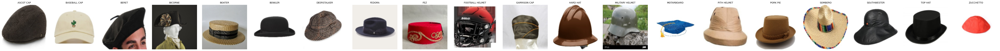

In [ ]:
import matplotlib.pyplot as plt

# 각 클래스별로 한 개씩 샘플을 저장할 딕셔너리 생성
class_samples = {}

for img, label in train_dataset:
    if label not in class_samples:
        class_samples[label] = img
    # 모든 클래스에 대한 샘플이 수집되면 종료
    if len(class_samples) == len(class_to_idx):
        break

# 클래스 수만큼 subplot 생성
num_classes = len(class_samples)
fig, axs = plt.subplots(1, num_classes, figsize=(num_classes * 3, 3))

# 각 클래스별로 저장된 이미지를 시각화
for label in range(num_classes):
    # 이미지 텐서: (C, H, W) -> (H, W, C)
    img = class_samples[label].permute(1, 2, 0).numpy()
    # 정규화 해제: (img * std + mean) mean=0.5, std=0.5이므로 [0,1] 범위로 변환
    img = img * 0.5 + 0.5
    axs[label].imshow(img)
    axs[label].axis('off')
    axs[label].set_title(idx_to_class[label], fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# 하이퍼파라미터 설정
latent_dim = 100  # 노이즈 벡터 크기
num_classes = len(class_to_idx)  # 데이터셋의 클래스 개수
image_size = 128  # 이미지 크기
epochs = 300  # 훈련 횟수

# 생성자 (Generator)
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)

        self.init_size = image_size // 16  # 128/16 = 8
        self.l1 = nn.Sequential(
            nn.Linear(latent_dim + num_classes, 512 * self.init_size * self.init_size),
            nn.ReLU(inplace=True)
        )

        # 4번의 업샘플링 블록을 사용하여 8->16->32->64->128의 해상도로 만들기
        self.conv_blocks = nn.Sequential(
            nn.BatchNorm2d(512),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1),  # 8 -> 16
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),  # 16 -> 32
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),   # 32 -> 64
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),    # 64 -> 128
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 3, kernel_size=3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, z, labels):
        label_input = self.label_emb(labels)
        x = torch.cat([z, label_input], dim=1)
        out = self.l1(x)
        out = out.view(x.size(0), 512, self.init_size, self.init_size)
        img = self.conv_blocks(out)
        return img

# 판별자 (Discriminator)
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)

        self.model = nn.Sequential(
            nn.Conv2d(3 + num_classes, 64, kernel_size=4, stride=2, padding=1),  # 128 -> 64
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),              # 64 -> 32
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),             # 32 -> 16
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1),             # 16 -> 8
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1024, kernel_size=4, stride=2, padding=1),            # 8 -> 4
            nn.BatchNorm2d(1024),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.adv_layer = nn.Sequential(
            nn.Linear(1024 * 4 * 4, 1),
            nn.Sigmoid()
        )

    def forward(self, img, labels):
        # 레이블 임베딩을 이미지와 같은 공간 크기로 확장하여 채널로 결합
        label_input = self.label_emb(labels).unsqueeze(2).unsqueeze(3)
        label_input = label_input.expand(img.size(0), num_classes, image_size, image_size)
        d_in = torch.cat((img, label_input), dim=1)
        out = self.model(d_in)
        out = out.view(out.size(0), -1)
        validity = self.adv_layer(out)
        return validity

In [ ]:
# 모델 초기화
generator = Generator().to(device)
discriminator = Discriminator().to(device)

criterion = nn.BCELoss()
optimizer_G = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

Epoch [1/300] | D Loss: 1.5465 | G Loss: 7.6169
Epoch [2/300] | D Loss: 0.9497 | G Loss: 4.2482
Epoch [3/300] | D Loss: 1.3102 | G Loss: 3.9877
Epoch [4/300] | D Loss: 1.0754 | G Loss: 2.4810
Epoch [5/300] | D Loss: 0.9296 | G Loss: 3.7335
Epoch [6/300] | D Loss: 1.4241 | G Loss: 2.0168
Epoch [7/300] | D Loss: 1.3201 | G Loss: 5.1391
Epoch [8/300] | D Loss: 1.9292 | G Loss: 0.4334
Epoch [9/300] | D Loss: 1.7886 | G Loss: 2.1810
Epoch [10/300] | D Loss: 1.2608 | G Loss: 5.7010
Epoch [11/300] | D Loss: 2.4012 | G Loss: 2.3548
Epoch [12/300] | D Loss: 1.1772 | G Loss: 0.4842
Epoch [13/300] | D Loss: 1.7797 | G Loss: 0.7932
Epoch [14/300] | D Loss: 1.8447 | G Loss: 0.6925
Epoch [15/300] | D Loss: 1.3856 | G Loss: 1.6758
Epoch [16/300] | D Loss: 1.4032 | G Loss: 0.4825
Epoch [17/300] | D Loss: 1.4562 | G Loss: 0.9378
Epoch [18/300] | D Loss: 1.5631 | G Loss: 0.4777
Epoch [19/300] | D Loss: 0.7230 | G Loss: 5.3146
Epoch [20/300] | D Loss: 1.3084 | G Loss: 3.4620
Epoch [21/300] | D Loss: 0.63

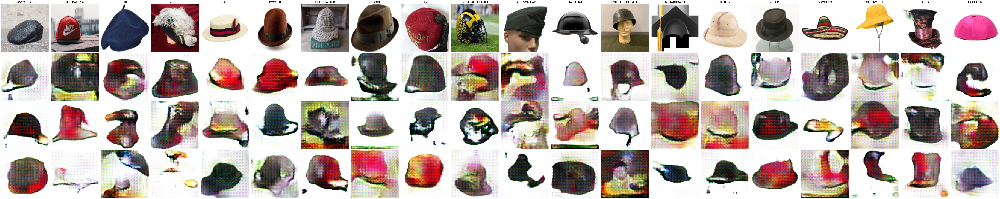

Epoch [51/300] | D Loss: 0.4088 | G Loss: 3.7295
Epoch [52/300] | D Loss: 3.0150 | G Loss: 0.3863
Epoch [53/300] | D Loss: 1.6221 | G Loss: 10.8366
Epoch [54/300] | D Loss: 2.6731 | G Loss: 0.6937
Epoch [55/300] | D Loss: 0.8485 | G Loss: 2.2211
Epoch [56/300] | D Loss: 1.1006 | G Loss: 1.9165
Epoch [57/300] | D Loss: 1.0110 | G Loss: 5.0420
Epoch [58/300] | D Loss: 0.3136 | G Loss: 7.3160
Epoch [59/300] | D Loss: 1.1257 | G Loss: 1.5749
Epoch [60/300] | D Loss: 2.8634 | G Loss: 0.3951
Epoch [61/300] | D Loss: 0.6450 | G Loss: 1.6488
Epoch [62/300] | D Loss: 1.6972 | G Loss: 0.6250
Epoch [63/300] | D Loss: 3.3796 | G Loss: 0.4103
Epoch [64/300] | D Loss: 0.4352 | G Loss: 9.0885
Epoch [65/300] | D Loss: 0.7525 | G Loss: 1.8349
Epoch [66/300] | D Loss: 2.2008 | G Loss: 9.5867
Epoch [67/300] | D Loss: 0.1924 | G Loss: 3.6294
Epoch [68/300] | D Loss: 0.0763 | G Loss: 4.6380
Epoch [69/300] | D Loss: 0.1160 | G Loss: 5.3603
Epoch [70/300] | D Loss: 1.2694 | G Loss: 0.5062
Epoch [71/300] | D 

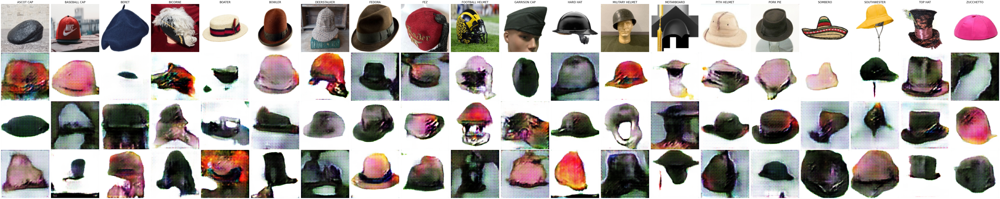

Epoch [101/300] | D Loss: 0.7255 | G Loss: 1.2014
Epoch [102/300] | D Loss: 0.5314 | G Loss: 5.8471
Epoch [103/300] | D Loss: 1.5460 | G Loss: 0.8430
Epoch [104/300] | D Loss: 0.8208 | G Loss: 3.2643
Epoch [105/300] | D Loss: 0.6316 | G Loss: 3.9243
Epoch [106/300] | D Loss: 0.1043 | G Loss: 5.1811
Epoch [107/300] | D Loss: 1.1171 | G Loss: 1.9508
Epoch [108/300] | D Loss: 0.1585 | G Loss: 4.8985
Epoch [109/300] | D Loss: 0.8206 | G Loss: 1.0446
Epoch [110/300] | D Loss: 0.0727 | G Loss: 5.0029
Epoch [111/300] | D Loss: 0.2455 | G Loss: 10.4757
Epoch [112/300] | D Loss: 0.4609 | G Loss: 4.7257
Epoch [113/300] | D Loss: 0.2633 | G Loss: 2.5928
Epoch [114/300] | D Loss: 0.0869 | G Loss: 4.5940
Epoch [115/300] | D Loss: 2.0865 | G Loss: 0.6861
Epoch [116/300] | D Loss: 0.5209 | G Loss: 2.7482
Epoch [117/300] | D Loss: 0.0847 | G Loss: 5.4530
Epoch [118/300] | D Loss: 0.0133 | G Loss: 6.7755
Epoch [119/300] | D Loss: 0.7625 | G Loss: 0.9309
Epoch [120/300] | D Loss: 1.4441 | G Loss: 1.4183

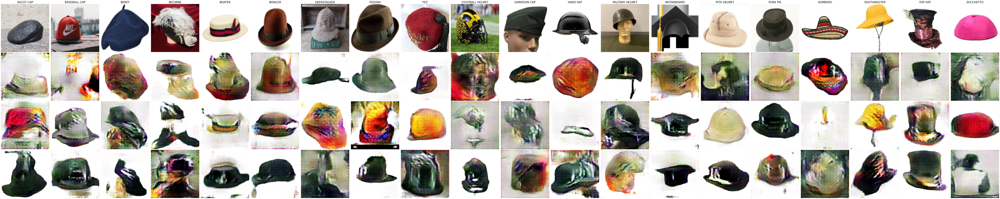

Epoch [151/300] | D Loss: 0.1460 | G Loss: 3.7250
Epoch [152/300] | D Loss: 0.0122 | G Loss: 7.5212
Epoch [153/300] | D Loss: 0.6840 | G Loss: 2.7917
Epoch [154/300] | D Loss: 0.2917 | G Loss: 4.6968
Epoch [155/300] | D Loss: 0.0192 | G Loss: 6.3752
Epoch [156/300] | D Loss: 0.0324 | G Loss: 4.7507
Epoch [157/300] | D Loss: 1.3141 | G Loss: 38.4705
Epoch [158/300] | D Loss: 0.0240 | G Loss: 5.2774
Epoch [159/300] | D Loss: 0.0482 | G Loss: 7.9984
Epoch [160/300] | D Loss: 0.0741 | G Loss: 7.3823
Epoch [161/300] | D Loss: 1.2747 | G Loss: 1.5794
Epoch [162/300] | D Loss: 0.4021 | G Loss: 2.5127
Epoch [163/300] | D Loss: 0.1698 | G Loss: 6.9109
Epoch [164/300] | D Loss: 0.3356 | G Loss: 2.7862
Epoch [165/300] | D Loss: 0.0789 | G Loss: 6.7942
Epoch [166/300] | D Loss: 0.0028 | G Loss: 8.8330
Epoch [167/300] | D Loss: 0.0020 | G Loss: 8.5688
Epoch [168/300] | D Loss: 0.0265 | G Loss: 8.2108
Epoch [169/300] | D Loss: 0.1291 | G Loss: 4.5856
Epoch [170/300] | D Loss: 0.0271 | G Loss: 7.6803

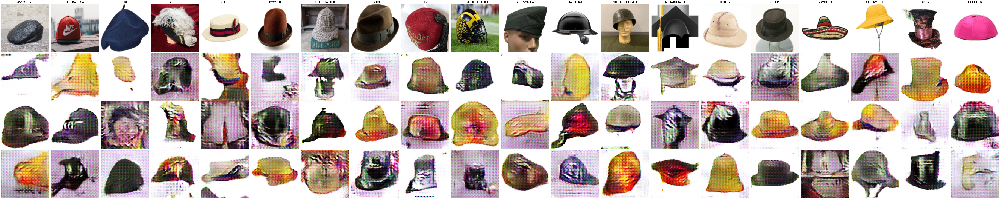

Epoch [201/300] | D Loss: 0.0027 | G Loss: 6.1699
Epoch [202/300] | D Loss: 0.0012 | G Loss: 7.9929
Epoch [203/300] | D Loss: 0.1676 | G Loss: 4.4793
Epoch [204/300] | D Loss: 0.2496 | G Loss: 4.8003
Epoch [205/300] | D Loss: 0.0013 | G Loss: 7.4552
Epoch [206/300] | D Loss: 0.5502 | G Loss: 0.7182
Epoch [207/300] | D Loss: 0.1714 | G Loss: 15.9949
Epoch [208/300] | D Loss: 0.0041 | G Loss: 8.8150
Epoch [209/300] | D Loss: 0.4910 | G Loss: 6.9053
Epoch [210/300] | D Loss: 0.1278 | G Loss: 6.1103
Epoch [211/300] | D Loss: 0.2717 | G Loss: 4.5701
Epoch [212/300] | D Loss: 0.0050 | G Loss: 9.3331
Epoch [213/300] | D Loss: 0.0157 | G Loss: 7.4339
Epoch [214/300] | D Loss: 1.6058 | G Loss: 0.8019
Epoch [215/300] | D Loss: 1.3475 | G Loss: 1.4229
Epoch [216/300] | D Loss: 0.0007 | G Loss: 9.0422
Epoch [217/300] | D Loss: 0.7149 | G Loss: 1.6754
Epoch [218/300] | D Loss: 0.0171 | G Loss: 6.8814
Epoch [219/300] | D Loss: 0.0134 | G Loss: 5.5713
Epoch [220/300] | D Loss: 0.5658 | G Loss: 5.5630

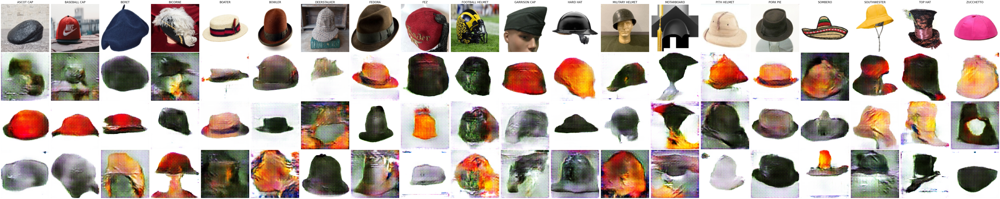

Epoch [251/300] | D Loss: 0.0042 | G Loss: 6.0856
Epoch [252/300] | D Loss: 0.6399 | G Loss: 3.7846
Epoch [253/300] | D Loss: 0.2111 | G Loss: 8.2108
Epoch [254/300] | D Loss: 0.2916 | G Loss: 1.5141
Epoch [255/300] | D Loss: 0.1035 | G Loss: 7.0508
Epoch [256/300] | D Loss: 0.0049 | G Loss: 5.8721
Epoch [257/300] | D Loss: 0.0006 | G Loss: 8.8882
Epoch [258/300] | D Loss: 0.0170 | G Loss: 8.0206
Epoch [259/300] | D Loss: 0.5225 | G Loss: 0.8664
Epoch [260/300] | D Loss: 0.0535 | G Loss: 7.0418
Epoch [261/300] | D Loss: 0.0122 | G Loss: 7.9398
Epoch [262/300] | D Loss: 1.0496 | G Loss: 2.0532
Epoch [263/300] | D Loss: 2.4517 | G Loss: 1.1017
Epoch [264/300] | D Loss: 0.0003 | G Loss: 9.7722
Epoch [265/300] | D Loss: 0.0047 | G Loss: 8.4550
Epoch [266/300] | D Loss: 0.3807 | G Loss: 5.2195
Epoch [267/300] | D Loss: 0.7007 | G Loss: 2.6237
Epoch [268/300] | D Loss: 0.0597 | G Loss: 8.9463
Epoch [269/300] | D Loss: 0.0089 | G Loss: 11.2567
Epoch [270/300] | D Loss: 0.0111 | G Loss: 6.6543

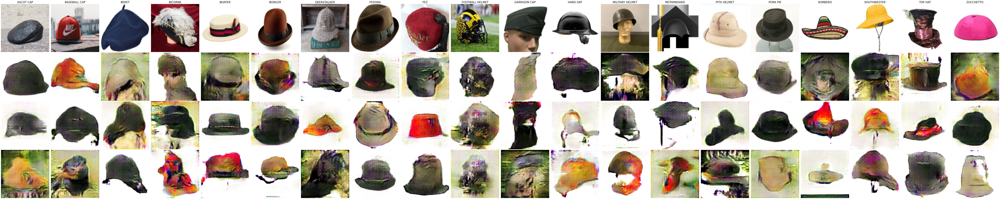

In [ ]:
# 학습 루프 (label smoothing 적용)
for epoch in range(epochs):
    for i, (real_imgs, labels) in enumerate(train_loader):
        current_batch_size = real_imgs.shape[0]
        real_imgs, labels = real_imgs.to(device), labels.to(device)

        # 진짜/가짜 라벨 설정
        real = torch.ones(current_batch_size, 1).to(device)
        fake = torch.zeros(current_batch_size, 1).to(device)

        # 판별자 학습
        optimizer_D.zero_grad()
        real_loss = criterion(discriminator(real_imgs, labels), real)

        z = torch.randn(current_batch_size, latent_dim).to(device)
        gen_imgs = generator(z, labels)
        fake_loss = criterion(discriminator(gen_imgs.detach(), labels), fake)
        d_loss = real_loss + fake_loss
        d_loss.backward()
        optimizer_D.step()

        # 생성자 학습 (label smoothing: 목표 레이블 0.9)
        optimizer_G.zero_grad()
        gen_target = torch.full((current_batch_size, 1), 0.9, device=device)
        g_loss = criterion(discriminator(gen_imgs, labels), gen_target)
        g_loss.backward()
        optimizer_G.step()

    print(f"Epoch [{epoch+1}/{epochs}] | D Loss: {d_loss.item():.4f} | G Loss: {g_loss.item():.4f}")

    # 50 에포크마다 시각화 (각 클래스별 그리드)
    if (epoch + 1) % 50 == 0:
        # 각 클래스별 진짜 이미지 1개씩 추출
        real_samples = {}
        for images, labs in test_loader:
            for idx, lab in enumerate(labs):
                cl = lab.item()
                if cl not in real_samples:
                    real_samples[cl] = images[idx].cpu().detach()
            if len(real_samples) == num_classes:
                break
        real_imgs_sorted = [real_samples[i] for i in range(num_classes)]

        # 각 클래스별로 Generator가 생성한 이미지 3개씩 생성
        gen_imgs_list = []
        for cls in range(num_classes):
            z = torch.randn(3, latent_dim).to(device)
            lab_tensor = torch.full((3,), cls, dtype=torch.long, device=device)
            gen_imgs_cls = generator(z, lab_tensor).cpu().detach()
            gen_imgs_list.append(gen_imgs_cls)

        # 3. 4행 x num_classes 열 그리드 생성 (figsize 조정)
        fig, ax = plt.subplots(4, num_classes, figsize=(5 * num_classes, 20))

        # 첫 번째 행: 각 클래스의 진짜 이미지
        for j in range(num_classes):
            img = real_imgs_sorted[j].numpy() * 0.5 + 0.5  # [-1,1] -> [0,1]
            ax[0, j].imshow(np.transpose(img, (1, 2, 0)))
            ax[0, j].axis("off")
            ax[0, j].set_title(idx_to_class[j], fontsize=20)

        # 두 번째~네 번째 행: 각 클래스별 생성 이미지 3개씩
        for j in range(num_classes):
            for k in range(3):
                img = gen_imgs_list[j][k].numpy() * 0.5 + 0.5
                ax[k+1, j].imshow(np.transpose(img, (1, 2, 0)))
                ax[k+1, j].axis("off")

        plt.tight_layout()
        plt.show()